# Bài toán 2 — Tank Battle: Kết quả thực nghiệm

So sánh 4 cấu hình tìm kiếm trên cùng mã nguồn của dự án:

| Ký hiệu | Thuật toán | Hàm đánh giá |
|---|---|---|
| MM | Minimax | Terminal |
| AB | Alpha-Beta | Terminal |
| H-MM | Minimax | Heuristic |
| H-AB | Alpha-Beta | Heuristic |

Nội dung: (1) kiểm thử, (2) benchmark thời gian/số nút, (3) đối đầu giữa các cấu hình.
Chạy bằng **Restart Kernel → Run All** (đặt notebook cùng thư mục với `task2/` và `tests/`).

## 1. Chuẩn bị

In [1]:
from pathlib import Path
import sys, random, subprocess
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục gốc của dự án
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "task2/game.py").is_file()), None)
assert ROOT is not None, "Hãy mở notebook trong thư mục dự án (có task2/ và tests/)."
sys.path[:0] = [str(ROOT), str(ROOT / "task2")]

from benchmark import build_scenarios, measure_one, validate_pairs, MODES_ORDER
from tournament import Tournament

# Tham số thí nghiệm
SCENARIOS = ["default", "open", "walls", "defense", "bullet"]
DEPTHS = [2, 4]        # độ sâu (ply)
REPEATS = 3            # số lần lặp mỗi phép đo
SEED = 42
LABELS = {"minimax": "MM", "alphabeta": "AB",
          "heuristic_minimax": "H-MM", "heuristic_alphabeta": "H-AB"}

cases = {name: build_scenarios()[name] for name in SCENARIOS}
print("Kịch bản:", list(cases))

Kịch bản: ['default', 'open', 'walls', 'defense', 'bullet']


## 2. Kiểm thử
Chạy bộ unit test có sẵn của dự án để chắc chắn cài đặt đúng (Minimax và Alpha-Beta cho cùng giá trị).

In [2]:
result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests"],
                        cwd=ROOT, capture_output=True, text=True)
print(result.stderr.strip().splitlines()[-3:] if result.stderr else result.stdout)
assert result.returncode == 0, "Có test không đạt!"
print("PASS: tất cả test đạt.")

['Ran 22 tests in 7.238s', '', '\x1bOK\x1b']
PASS: tất cả test đạt.


## 3. Benchmark: cùng trạng thái, cùng độ sâu

Mỗi cấu hình chạy trên 5 kịch bản × 2 bên (P0/P1) × 2 độ sâu (2, 4) × 3 lần lặp
= **240 lượt đo**. Ghi lại thời gian, số nút duyệt và số lần cắt nhánh.

In [3]:
rng = random.Random(SEED)
rows = []
for scenario, state in cases.items():
    for player in (0, 1):
        for depth in DEPTHS:
            for repeat in range(1, REPEATS + 1):
                modes = list(MODES_ORDER)
                rng.shuffle(modes)          # xáo thứ tự để công bằng
                for mode in modes:
                    rows.append(measure_one(state, scenario, player, depth, mode, repeat))

bench = pd.DataFrame(rows)
# Kiểm tra: MM và AB (cùng evaluator) phải cho cùng giá trị
print(f"{len(bench)} lượt đo, {validate_pairs(rows)} cặp MM/AB khớp giá trị.")

240 lượt đo, 120 cặp MM/AB khớp giá trị.


### Bảng kết quả (trung bình)

In [4]:
summary = (bench.groupby(["depth", "mode"])
           .agg(time_ms=("time_ms", "mean"), nodes=("nodes", "mean"),
                cutoffs=("cutoffs", "mean"))
           .reindex(pd.MultiIndex.from_product([DEPTHS, MODES_ORDER]))
           .round(2))
display(summary)

# Alpha-Beta nhanh hơn / ít nút hơn Minimax bao nhiêu?
for depth in DEPTHS:
    for mm, ab, name in (("minimax", "alphabeta", "Terminal"),
                         ("heuristic_minimax", "heuristic_alphabeta", "Heuristic")):
        t = summary.loc[(depth, mm), "time_ms"] / summary.loc[(depth, ab), "time_ms"]
        n = 1 - summary.loc[(depth, ab), "nodes"] / summary.loc[(depth, mm), "nodes"]
        print(f"Depth {depth} - {name}: Alpha-Beta nhanh gấp {t:.1f} lần, giảm {n:.0%} số nút")

time_ms   nodes  cutoffs
2 minimax                 0.51    40.6      0.0
  alphabeta               0.27    17.4      4.8
  heuristic_minimax       7.81    40.6      0.0
  heuristic_alphabeta     4.90    18.9      4.5
4 minimax                12.96  1329.1      0.0
  alphabeta               1.73   120.2     41.6
  heuristic_minimax      46.47  1329.1      0.0
  heuristic_alphabeta    14.37   190.7     48.2

Depth 2 - Terminal: Alpha-Beta nhanh gấp 1.9 lần, giảm 57% số nút
Depth 2 - Heuristic: Alpha-Beta nhanh gấp 1.6 lần, giảm 53% số nút
Depth 4 - Terminal: Alpha-Beta nhanh gấp 7.5 lần, giảm 91% số nút
Depth 4 - Heuristic: Alpha-Beta nhanh gấp 3.2 lần, giảm 86% số nút


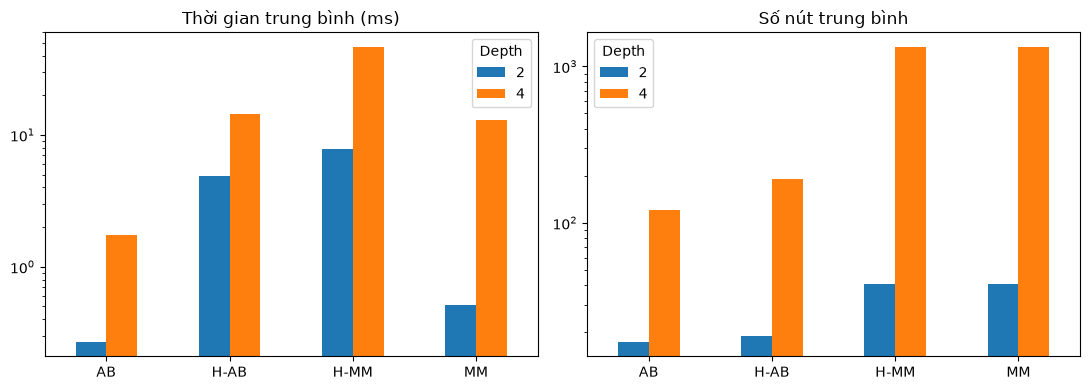

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["time_ms", "nodes"],
                          ["Thời gian trung bình (ms)", "Số nút trung bình"]):
    data = summary[col].unstack(0).rename(index=LABELS)
    data.plot.bar(ax=ax, rot=0)
    ax.set_title(title); ax.set_xlabel(""); ax.legend(title="Depth")
    ax.set_yscale("log")   # thang log vì chênh lệch lớn
plt.tight_layout(); plt.show()

## 4. Đối đầu giữa các cấu hình

Mỗi cặp trong 4 cấu hình đấu với nhau, đổi bên, trên 5 kịch bản
→ 6 cặp × 2 bên × 5 kịch bản = **60 trận** (depth 3, tối đa 60 lượt/trận).
Trận chưa phân thắng bại sau 60 lượt tính là *chưa kết thúc* (không phải hòa).
Bước này có thể mất vài phút.

In [6]:
runner = Tournament(depth=3, max_cycles=60, time_limit_ms=None)
games = runner.run(cases, list(MODES_ORDER))
table = (pd.DataFrame(runner.summarize(games)).set_index("mode")
         .loc[list(MODES_ORDER)][["games", "wins", "losses", "draws", "unfinished"]])
table.index = [LABELS[m] for m in table.index]
display(table)

default: P0 minimax / P1 alphabeta: unfinished, experiment_cycle_limit, 60 cycles
default: P0 alphabeta / P1 minimax: unfinished, experiment_cycle_limit, 60 cycles
default: P0 minimax / P1 heuristic_minimax: 1, destroyed, 14 cycles
default: P0 heuristic_minimax / P1 minimax: 0, destroyed, 14 cycles
default: P0 minimax / P1 heuristic_alphabeta: 1, destroyed, 14 cycles
default: P0 heuristic_alphabeta / P1 minimax: 0, destroyed, 14 cycles
default: P0 alphabeta / P1 heuristic_minimax: 1, destroyed, 14 cycles
default: P0 heuristic_minimax / P1 alphabeta: 0, destroyed, 14 cycles
default: P0 alphabeta / P1 heuristic_alphabeta: 1, destroyed, 14 cycles
default: P0 heuristic_alphabeta / P1 alphabeta: 0, destroyed, 14 cycles
default: P0 heuristic_minimax / P1 heuristic_alphabeta: draw, mutual_destruction, 14 cycles
default: P0 heuristic_alphabeta / P1 heuristic_minimax: draw, mutual_destruction, 14 cycles
open: P0 minimax / P1 alphabeta: unfinished, experiment_cycle_limit, 60 cycles
open: P0 alph

,games,wins,losses,draws,unfinished
MM,30,3,19,0,8
AB,30,3,19,0,8
H-MM,30,19,3,8,0
H-AB,30,19,3,8,0


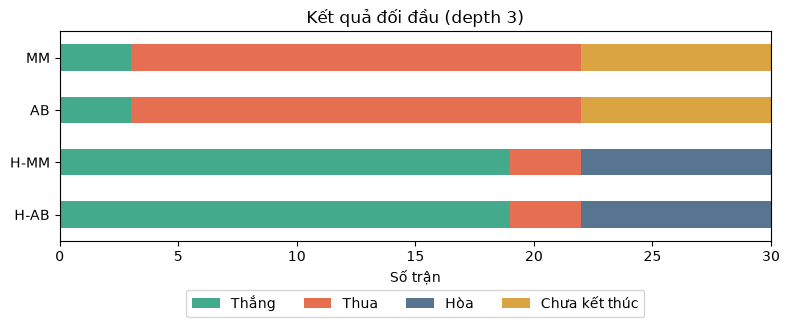

In [7]:
table[["wins", "losses", "draws", "unfinished"]].plot.barh(
    stacked=True, figsize=(8, 3.5),
    color=["#43aa8b", "#e76f51", "#577590", "#d9a441"])
plt.gca().invert_yaxis()
plt.xlabel("Số trận"); plt.title("Kết quả đối đầu (depth 3)")
plt.legend(["Thắng", "Thua", "Hòa", "Chưa kết thúc"], ncol=4,
           loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

## 5. Nhận xét

- **Hiệu quả tìm kiếm:** Alpha-Beta cho cùng giá trị với Minimax nhưng duyệt ít nút
  và chạy nhanh hơn rõ rệt; độ sâu càng lớn, lợi ích càng lớn.
- **Heuristic:** giúp phân biệt các trạng thái chưa kết thúc nên chọn nước đi tốt hơn,
  đổi lại tốn thêm chi phí tính toán mỗi nút.
- **Hiệu quả tìm kiếm ≠ kết quả chơi:** hai phép so sánh này độc lập nhau
  (xem bảng ở mục 3 và mục 4).
- **Giới hạn:** kết luận chỉ đúng với 5 kịch bản, độ sâu và số lượt đã thử,
  và chỉ đo trên máy chạy notebook này.